In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from tqdm.auto import tqdm

# --------------------------------------------------
# Project
# --------------------------------------------------
PROJECT_ROOT = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

# --------------------------------------------------
# Dataset CSVs
# --------------------------------------------------
TRAIN_CSV = (
    PROJECT_ROOT
    / "Dataset"
    / "GOES_TrainNEW"
    / "train_triplets.csv"
)

TEST_CSV = (
    PROJECT_ROOT
    / "Dataset"
    / "GOES_TestNEW"
    / "test_triplets.csv"
)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("TRAIN_CSV:", TRAIN_CSV)
print("TEST_CSV:", TEST_CSV)

print("\nTrain CSV exists:", TRAIN_CSV.exists())
print("Test CSV exists:", TEST_CSV.exists())

PROJECT_ROOT: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation
TRAIN_CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TrainNEW/train_triplets.csv
TEST_CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestNEW/test_triplets.csv

Train CSV exists: True
Test CSV exists: True


In [2]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training triplets:", len(train_df))
print("Testing triplets:", len(test_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("\nFirst training triplet:")
display(train_df.head(1))

print("\nFirst testing triplet:")
display(test_df.head(1))

Training triplets: 1014
Testing triplets: 253

Training columns:
['input_0', 'target', 'input_2', 'time_0', 'time_1', 'time_2']

Testing columns:
['input_0', 'target', 'input_2', 'time_0', 'time_1', 'time_2']

First training triplet:


,input_0,target,input_2,time_0,time_1,time_2
0,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:00:20,2026-07-07 00:10:20,2026-07-07 00:20:20



First testing triplet:


,input_0,target,input_2,time_0,time_1,time_2
0,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-14 01:50:20,2026-07-14 02:00:20,2026-07-14 02:10:20


In [3]:
BT_LOW = 200.0
BT_HIGH = 320.0

print("Brightness Temperature normalization:")
print("Lower bound:", BT_LOW, "K")
print("Upper bound:", BT_HIGH, "K")

Brightness Temperature normalization:
Lower bound: 200.0 K
Upper bound: 320.0 K


In [4]:
def radiance_to_bt(ds):
    """
    Convert GOES ABI radiance to brightness temperature (Kelvin).

    Uses Planck coefficients stored in the NetCDF file.
    """

    rad = ds["Rad"].values.astype(np.float32)

    FK1 = float(ds["planck_fk1"].values)
    FK2 = float(ds["planck_fk2"].values)
    BC1 = float(ds["planck_bc1"].values)
    BC2 = float(ds["planck_bc2"].values)

    bt = np.full(
        rad.shape,
        np.nan,
        dtype=np.float32
    )

    valid = (
        np.isfinite(rad)
        & (rad > 0)
    )

    bt[valid] = (
        FK2 /
        np.log((FK1 / rad[valid]) + 1.0)
    )

    bt[valid] = (
        (bt[valid] - BC1) / BC2
    )

    return bt

In [5]:
def create_goes_earth_mask(ds):
    """
    Create Earth-disk mask using the GOES geostationary
    projection geometry.
    """

    H = float(
        ds["goes_imager_projection"]
        .perspective_point_height
    )

    r_eq = float(
        ds["goes_imager_projection"]
        .semi_major_axis
    )

    r_pol = float(
        ds["goes_imager_projection"]
        .semi_minor_axis
    )

    H_sat = H + r_eq

    x = ds["x"].values.astype(np.float32)
    y = ds["y"].values.astype(np.float32)

    xx = x[None, :]
    yy = y[:, None]

    sin_x = np.sin(xx)
    cos_x = np.cos(xx)

    sin_y = np.sin(yy)
    cos_y = np.cos(yy)

    A = (
        sin_x**2
        +
        cos_x**2
        *
        (
            cos_y**2
            +
            (r_eq**2 / r_pol**2)
            * sin_y**2
        )
    )

    B = (
        -2.0
        * H_sat
        * cos_x
        * cos_y
    )

    C = (
        H_sat**2
        - r_eq**2
    )

    discriminant = (
        B**2
        - 4.0 * A * C
    )

    earth_mask = discriminant >= 0

    return earth_mask

In [6]:
def preprocess_goes_file(
    file_path,
    bt_low=200.0,
    bt_high=320.0
):
    """
    GOES preprocessing:

    NetCDF
       ↓
    Radiance
       ↓
    Brightness Temperature
       ↓
    Earth mask
       ↓
    DQF == 0
       ↓
    Fixed 200-320 K normalization
       ↓
    Invalid pixels = 0 for model input

    Returns:
        normalized_image
        valid_mask
    """

    with xr.open_dataset(file_path) as ds:

        # -----------------------------------------
        # 1. Radiance → Brightness Temperature
        # -----------------------------------------
        bt = radiance_to_bt(ds)

        # -----------------------------------------
        # 2. Earth mask
        # -----------------------------------------
        earth_mask = create_goes_earth_mask(ds)

        # -----------------------------------------
        # 3. DQF mask
        # -----------------------------------------
        dqf = ds["DQF"].values

        # -----------------------------------------
        # 4. Final valid mask
        # -----------------------------------------
        valid_mask = (
            earth_mask
            & (dqf == 0)
            & np.isfinite(bt)
        )

        # -----------------------------------------
        # 5. Fixed normalization
        # -----------------------------------------
        image = (
            (bt - bt_low)
            / (bt_high - bt_low)
        )

        image = np.clip(
            image,
            0.0,
            1.0
        )

        # -----------------------------------------
        # 6. Replace invalid pixels
        # -----------------------------------------
        image[~valid_mask] = 0.0

        # -----------------------------------------
        # 7. Final numerical safety
        # -----------------------------------------
        image = np.nan_to_num(
            image,
            nan=0.0,
            posinf=1.0,
            neginf=0.0
        )

        return (
            image.astype(np.float32),
            valid_mask.astype(np.uint8)
        )

In [7]:
PREPROCESS_ROOT = (
    PROJECT_ROOT
    / "Dataset"
    / "GOES_Preprocessed_200_320"
)

TRAIN_IMAGE_DIR = (
    PREPROCESS_ROOT
    / "train"
    / "images"
)

TRAIN_MASK_DIR = (
    PREPROCESS_ROOT
    / "train"
    / "masks"
)

TEST_IMAGE_DIR = (
    PREPROCESS_ROOT
    / "test"
    / "images"
)

TEST_MASK_DIR = (
    PREPROCESS_ROOT
    / "test"
    / "masks"
)

for directory in [
    TRAIN_IMAGE_DIR,
    TRAIN_MASK_DIR,
    TEST_IMAGE_DIR,
    TEST_MASK_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Preprocessing directories created.")
print(PREPROCESS_ROOT)

Preprocessing directories created.
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320


In [8]:
FRAME_COLUMNS = [
    "input_0",
    "target",
    "input_2"
]

train_files = set()

for col in FRAME_COLUMNS:
    train_files.update(
        train_df[col].tolist()
    )

test_files = set()

for col in FRAME_COLUMNS:
    test_files.update(
        test_df[col].tolist()
    )

print("Unique training frames:", len(train_files))
print("Unique testing frames:", len(test_files))

overlap = train_files.intersection(test_files)

print("Train/Test frame overlap:", len(overlap))

Unique training frames: 1018
Unique testing frames: 255
Train/Test frame overlap: 0


In [9]:
missing_train = [
    p for p in train_files
    if not Path(p).exists()
]

missing_test = [
    p for p in test_files
    if not Path(p).exists()
]

print("Missing training files:", len(missing_train))
print("Missing testing files:", len(missing_test))

if missing_train:
    print("\nFirst missing training file:")
    print(missing_train[0])

if missing_test:
    print("\nFirst missing testing file:")
    print(missing_test[0])

Missing training files: 0
Missing testing files: 0


In [10]:
def output_name_from_input(file_path):
    return Path(file_path).stem + ".npy"

In [11]:
train_metadata = []

for file_path in tqdm(
    sorted(train_files),
    desc="Preprocessing training frames"
):

    file_path = Path(file_path)

    output_image = (
        TRAIN_IMAGE_DIR
        / output_name_from_input(file_path)
    )

    output_mask = (
        TRAIN_MASK_DIR
        / output_name_from_input(file_path)
    )

    # Skip if already processed
    if output_image.exists() and output_mask.exists():

        train_metadata.append({
            "original_path": str(file_path),
            "image_path": str(output_image),
            "mask_path": str(output_mask)
        })

        continue

    image, mask = preprocess_goes_file(
        file_path,
        bt_low=BT_LOW,
        bt_high=BT_HIGH
    )

    np.save(
        output_image,
        image
    )

    np.save(
        output_mask,
        mask
    )

    train_metadata.append({
        "original_path": str(file_path),
        "image_path": str(output_image),
        "mask_path": str(output_mask)
    })

print("\nTraining preprocessing completed.")
print("Frames processed:", len(train_metadata))

Preprocessing training frames:   0%|          | 0/1018 [00:00<?, ?it/s]


Training preprocessing completed.
Frames processed: 1018


In [12]:
BT_LOW = 200
BT_HIGH = 320

In [13]:
test_metadata = []

for file_path in tqdm(
    sorted(test_files),
    desc="Preprocessing testing frames"
):

    file_path = Path(file_path)

    output_image = (
        TEST_IMAGE_DIR
        / output_name_from_input(file_path)
    )

    output_mask = (
        TEST_MASK_DIR
        / output_name_from_input(file_path)
    )

    # Skip if already processed
    if output_image.exists() and output_mask.exists():

        test_metadata.append({
            "original_path": str(file_path),
            "image_path": str(output_image),
            "mask_path": str(output_mask)
        })

        continue

    image, mask = preprocess_goes_file(
        file_path,
        bt_low=BT_LOW,
        bt_high=BT_HIGH
    )

    np.save(
        output_image,
        image
    )

    np.save(
        output_mask,
        mask
    )

    test_metadata.append({
        "original_path": str(file_path),
        "image_path": str(output_image),
        "mask_path": str(output_mask)
    })

print("\nTesting preprocessing completed.")
print("Frames processed:", len(test_metadata))

Preprocessing testing frames:   0%|          | 0/255 [00:00<?, ?it/s]


Testing preprocessing completed.
Frames processed: 255


In [14]:
train_meta_df = pd.DataFrame(
    train_metadata
)

test_meta_df = pd.DataFrame(
    test_metadata
)

TRAIN_META_CSV = (
    PREPROCESS_ROOT
    / "train_frame_metadata.csv"
)

TEST_META_CSV = (
    PREPROCESS_ROOT
    / "test_frame_metadata.csv"
)

train_meta_df.to_csv(
    TRAIN_META_CSV,
    index=False
)

test_meta_df.to_csv(
    TEST_META_CSV,
    index=False
)

print("Training metadata:")
print(TRAIN_META_CSV)

print("\nTesting metadata:")
print(TEST_META_CSV)

Training metadata:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train_frame_metadata.csv

Testing metadata:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/test_frame_metadata.csv


In [15]:
train_lookup = {
    row["original_path"]: {
        "image": row["image_path"],
        "mask": row["mask_path"]
    }
    for _, row in train_meta_df.iterrows()
}

test_lookup = {
    row["original_path"]: {
        "image": row["image_path"],
        "mask": row["mask_path"]
    }
    for _, row in test_meta_df.iterrows()
}

print("Training lookup entries:", len(train_lookup))
print("Testing lookup entries:", len(test_lookup))

Training lookup entries: 1018
Testing lookup entries: 255


In [16]:
preprocessed_train_rows = []

for _, row in train_df.iterrows():

    preprocessed_train_rows.append({
        "input_0": train_lookup[row["input_0"]]["image"],
        "target":  train_lookup[row["target"]]["image"],
        "input_2": train_lookup[row["input_2"]]["image"],

        "mask_0": train_lookup[row["input_0"]]["mask"],
        "mask_target": train_lookup[row["target"]]["mask"],
        "mask_2": train_lookup[row["input_2"]]["mask"],

        "time_0": row["time_0"],
        "time_1": row["time_1"],
        "time_2": row["time_2"]
    })

preprocessed_train_df = pd.DataFrame(
    preprocessed_train_rows
)

PREPROCESSED_TRAIN_CSV = (
    PREPROCESS_ROOT
    / "train_triplets_preprocessed.csv"
)

preprocessed_train_df.to_csv(
    PREPROCESSED_TRAIN_CSV,
    index=False
)

print("Preprocessed training triplets:")
print(PREPROCESSED_TRAIN_CSV)

print("Triplets:", len(preprocessed_train_df))

display(
    preprocessed_train_df.head()
)

Preprocessed training triplets:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train_triplets_preprocessed.csv
Triplets: 1014


,input_0,target,input_2,mask_0,mask_target,mask_2,time_0,time_1,time_2
0,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-07 00:00:20,2026-07-07 00:10:20,2026-07-07 00:20:20
1,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-07 00:10:20,2026-07-07 00:20:20,2026-07-07 00:30:20
2,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-07 00:20:20,2026-07-07 00:30:20,2026-07-07 00:40:20
3,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-07 00:30:20,2026-07-07 00:40:20,2026-07-07 00:50:20
4,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-07 00:40:20,2026-07-07 00:50:20,2026-07-07 01:00:20


In [17]:
preprocessed_test_rows = []

for _, row in test_df.iterrows():

    preprocessed_test_rows.append({
        "input_0": test_lookup[row["input_0"]]["image"],
        "target":  test_lookup[row["target"]]["image"],
        "input_2": test_lookup[row["input_2"]]["image"],

        "mask_0": test_lookup[row["input_0"]]["mask"],
        "mask_target": test_lookup[row["target"]]["mask"],
        "mask_2": test_lookup[row["input_2"]]["mask"],

        "time_0": row["time_0"],
        "time_1": row["time_1"],
        "time_2": row["time_2"]
    })

preprocessed_test_df = pd.DataFrame(
    preprocessed_test_rows
)

PREPROCESSED_TEST_CSV = (
    PREPROCESS_ROOT
    / "test_triplets_preprocessed.csv"
)

preprocessed_test_df.to_csv(
    PREPROCESSED_TEST_CSV,
    index=False
)

print("Preprocessed testing triplets:")
print(PREPROCESSED_TEST_CSV)

print("Triplets:", len(preprocessed_test_df))

display(
    preprocessed_test_df.head()
)

Preprocessed testing triplets:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/test_triplets_preprocessed.csv
Triplets: 253


,input_0,target,input_2,mask_0,mask_target,mask_2,time_0,time_1,time_2
0,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 01:50:20,2026-07-14 02:00:20,2026-07-14 02:10:20
1,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 02:00:20,2026-07-14 02:10:20,2026-07-14 02:20:20
2,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 02:10:20,2026-07-14 02:20:20,2026-07-14 02:30:20
3,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 02:20:20,2026-07-14 02:30:20,2026-07-14 02:40:20
4,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 02:30:20,2026-07-14 02:40:20,2026-07-14 02:50:20


In [18]:
row = preprocessed_train_df.iloc[0]

img0 = np.load(row["input_0"])
gt = np.load(row["target"])
img2 = np.load(row["input_2"])

mask0 = np.load(row["mask_0"])
mask_gt = np.load(row["mask_target"])
mask2 = np.load(row["mask_2"])

print("Input 0:")
print("Shape:", img0.shape)
print("dtype:", img0.dtype)
print("NaN:", np.isnan(img0).sum())
print("Min:", img0.min())
print("Max:", img0.max())

print("\nGT:")
print("Shape:", gt.shape)
print("dtype:", gt.dtype)
print("NaN:", np.isnan(gt).sum())
print("Min:", gt.min())
print("Max:", gt.max())

print("\nInput 2:")
print("Shape:", img2.shape)
print("dtype:", img2.dtype)
print("NaN:", np.isnan(img2).sum())
print("Min:", img2.min())
print("Max:", img2.max())

print("\nGT valid pixels:", mask_gt.sum())
print("GT valid percentage:", mask_gt.mean() * 100)

Input 0:
Shape: (5424, 5424)
dtype: float32
NaN: 0
Min: 0.0
Max: 0.9817861

GT:
Shape: (5424, 5424)
dtype: float32
NaN: 0
Min: 0.0
Max: 0.97798234

Input 2:
Shape: (5424, 5424)
dtype: float32
NaN: 0
Min: 0.0
Max: 0.97194797

GT valid pixels: 23046185
GT valid percentage: 78.33569161097623


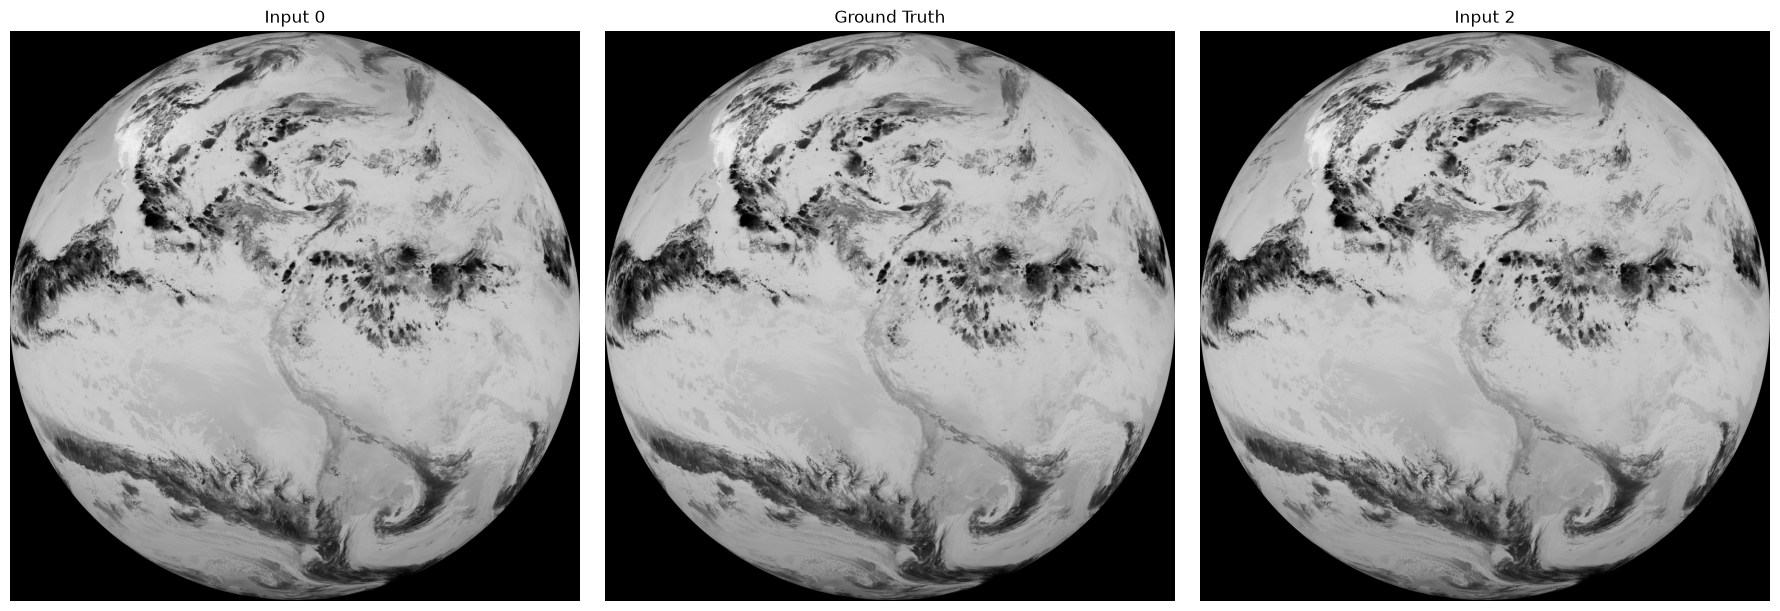

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

axes[0].imshow(
    img0,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0].set_title("Input 0")
axes[0].axis("off")

axes[1].imshow(
    gt,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title("Ground Truth")
axes[1].axis("off")

axes[2].imshow(
    img2,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[2].set_title("Input 2")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [20]:
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd


class GOESRIFEDataset(Dataset):

    def __init__(self, csv_file):

        self.df = pd.read_csv(csv_file)

        print("Dataset:", csv_file)
        print("Number of triplets:", len(self.df))

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # ---------------------------------------
        # Load preprocessed images
        # ---------------------------------------
        img0 = np.load(row["input_0"]).astype(np.float32)
        gt   = np.load(row["target"]).astype(np.float32)
        img2 = np.load(row["input_2"]).astype(np.float32)

        # ---------------------------------------
        # Load valid masks
        # ---------------------------------------
        mask0 = np.load(row["mask_0"]).astype(np.float32)
        mask_gt = np.load(row["mask_target"]).astype(np.float32)
        mask2 = np.load(row["mask_2"]).astype(np.float32)

        # ---------------------------------------
        # Convert [H,W] → [1,H,W]
        # ---------------------------------------
        img0 = torch.from_numpy(img0).unsqueeze(0)
        gt   = torch.from_numpy(gt).unsqueeze(0)
        img2 = torch.from_numpy(img2).unsqueeze(0)

        mask0 = torch.from_numpy(mask0).unsqueeze(0)
        mask_gt = torch.from_numpy(mask_gt).unsqueeze(0)
        mask2 = torch.from_numpy(mask2).unsqueeze(0)

        # ---------------------------------------
        # RIFE expects 3 channels
        # ---------------------------------------
        img0 = img0.repeat(3, 1, 1)
        gt   = gt.repeat(3, 1, 1)
        img2 = img2.repeat(3, 1, 1)

        return {
            "img0": img0,
            "gt": gt,
            "img2": img2,

            "mask0": mask0,
            "mask_gt": mask_gt,
            "mask2": mask2,

            "time0": row["time_0"],
            "time1": row["time_1"],
            "time2": row["time_2"]
        }

In [21]:
train_dataset = GOESRIFEDataset(
    PREPROCESSED_TRAIN_CSV
)

test_dataset = GOESRIFEDataset(
    PREPROCESSED_TEST_CSV
)

Dataset: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train_triplets_preprocessed.csv
Number of triplets: 1014
Dataset: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/test_triplets_preprocessed.csv
Number of triplets: 253


In [22]:
sample = train_dataset[0]

print("img0:", sample["img0"].shape)
print("gt:", sample["gt"].shape)
print("img2:", sample["img2"].shape)

print("mask0:", sample["mask0"].shape)
print("mask_gt:", sample["mask_gt"].shape)
print("mask2:", sample["mask2"].shape)

print("\nimg0 dtype:", sample["img0"].dtype)
print("gt dtype:", sample["gt"].dtype)

print("\nimg0 min:", sample["img0"].min().item())
print("img0 max:", sample["img0"].max().item())

print("\nGT valid pixels:", sample["mask_gt"].sum().item())
print(
    "GT valid percentage:",
    sample["mask_gt"].mean().item() * 100
)

print("\nTimes:")
print(sample["time0"])
print(sample["time1"])
print(sample["time2"])

img0: torch.Size([3, 5424, 5424])
gt: torch.Size([3, 5424, 5424])
img2: torch.Size([3, 5424, 5424])
mask0: torch.Size([1, 5424, 5424])
mask_gt: torch.Size([1, 5424, 5424])
mask2: torch.Size([1, 5424, 5424])

img0 dtype: torch.float32
gt dtype: torch.float32

img0 min: 0.0
img0 max: 0.9817860722541809

GT valid pixels: 23046184.0
GT valid percentage: 78.33569049835205

Times:
2026-07-07 00:00:20
2026-07-07 00:10:20
2026-07-07 00:20:20


In [23]:
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 1014
Test batches: 253


In [24]:
batch = next(iter(train_loader))

print("img0:", batch["img0"].shape)
print("gt:", batch["gt"].shape)
print("img2:", batch["img2"].shape)

print("mask_gt:", batch["mask_gt"].shape)

print("\nimg0 NaN:",
      torch.isnan(batch["img0"]).sum().item())

print("gt NaN:",
      torch.isnan(batch["gt"]).sum().item())

print("img2 NaN:",
      torch.isnan(batch["img2"]).sum().item())

img0: torch.Size([1, 3, 5424, 5424])
gt: torch.Size([1, 3, 5424, 5424])
img2: torch.Size([1, 3, 5424, 5424])
mask_gt: torch.Size([1, 1, 5424, 5424])

img0 NaN: 0
gt NaN: 0
img2 NaN: 0


In [25]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

img0 = batch["img0"].to(
    device,
    non_blocking=True
)

gt = batch["gt"].to(
    device,
    non_blocking=True
)

img2 = batch["img2"].to(
    device,
    non_blocking=True
)

mask_gt = batch["mask_gt"].to(
    device,
    non_blocking=True
)

print("img0:", img0.shape, img0.device)
print("gt:", gt.shape, gt.device)
print("img2:", img2.shape, img2.device)
print("mask:", mask_gt.shape, mask_gt.device)

Device: cuda
img0: torch.Size([1, 3, 5424, 5424]) cuda:0
gt: torch.Size([1, 3, 5424, 5424]) cuda:0
img2: torch.Size([1, 3, 5424, 5424]) cuda:0
mask: torch.Size([1, 1, 5424, 5424]) cuda:0


In [26]:
rife_input = torch.cat(
    [img0, img2, gt],
    dim=1
)

print("RIFE input:", rife_input.shape)

print(
    "NaN:",
    torch.isnan(rife_input).sum().item()
)

print(
    "Inf:",
    torch.isinf(rife_input).sum().item()
)

RIFE input: torch.Size([1, 9, 5424, 5424])
NaN: 0
Inf: 0


In [28]:

import os
import sys
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT = os.path.expanduser(
    "~/Satellite_Frame_Interpolation"
)

RIFE_ROOT = os.path.join(
    ROOT,
    "Official_RIFE"
)

In [29]:
if RIFE_ROOT not in sys.path:
    sys.path.insert(0, RIFE_ROOT)

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

In [30]:
from model.RIFE import Model

model = Model()

print("Official RIFE Model created successfully.")

Official RIFE Model created successfully.


In [31]:
from model.IFNet import IFNet

In [32]:
from model.IFNet import IFNet

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

model = IFNet().to(device)

print("RIFE model loaded.")

RIFE model loaded.


In [33]:
num_params = sum(
    p.numel()
    for p in model.parameters()
)

print(
    f"Total parameters: {num_params:,}"
)

print(
    f"Total parameters: "
    f"{num_params / 1e6:.2f} M"
)

Total parameters: 10,708,215
Total parameters: 10.71 M
